**Seda Kart**

General Research Project

**Generative AI Declaration**

Claude (Anthropic) was used to write and debug code in this notebook and to improve figures. Decisions on cohort design, model selection, and treatment of class imbalance were made by the project team. All code was checked and executed by me before its outputs were used in the report. Full AI use declaration can be found in the report.

# Phase 1: Data Preparation and Cohort Construction

**Project:** Student Dropout Survival Analysis (Bayes 26D)
**Random seed:** 42 (set globally for reproducibility)

## What this notebook does

Reads the raw dataset of 18,724 students and produces four analysis-ready cohorts, each in a with-engagement and no-engagement variant.

**Input:** `Bayes 26D.csv`, behavioural dataset from an online learning platform, provided by the industry partner. The dataset include 18,724 students across eighteen columns with no date column

**Outputs:**

* `cohort_1.parquet` to `cohort_4.parquet` in `data/processed/`, containing the four cohort datasets with engineered features and a per-cohort binary target
* `cohort_1_noeng.parquet` to `cohort_4_noeng.parquet` in `data/processed/`, containing the same cohorts with the engagement features removed for the Phase 2 with/without-engagement comparison
* CSV copies of all eight cohort datasets in `data/processed/csv/`
* `cohort_summary.csv`, `session_trajectory_by_group.csv`, and `lifespan4_grade_comparison.csv` in `outputs/tables/`
* `population_cascade.png`, `dropout_rate_by_cohort.png`, and `session_trajectory_by_group.png` in `outputs/figures/`

## Why the data is split this way

Student records end at structured course checkpoints. Once a record becomes missing, it does not resume in a later course column. The missingness is monotone, and it is not a defect: it records the exit itself.

That rules out imputation. Filling a departed student's later columns would mean inventing session attendance and test grades for someone who was never there, across 5,092 records, and every downstream model would then treat those inventions as observations.

Splitting on the natural dropout points is the standard alternative in survival analysis wherever such points exist. Each cohort holds only students present throughout it, so no cohort contains a missing value and no imputation decision arises. The cost is that one prediction problem becomes four: each cohort asks whether a student present at that checkpoint survives to the next. Section 1.2 evidences the monotone pattern; the cohorts are constructed in Section 1.7.

## 1.0 Environment setup

Imports, output directories, and the random seed. Seed 42 is fixed here and used by every random operation in this notebook.

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

# Suppressing minor warnings for cleaner notebook output
warnings.filterwarnings('ignore', category=FutureWarning)

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Project directory structure
# Phase 1 writes here, Phases 2 and 3 read from it.
PROCESSED_DIR = Path('data/processed')
FIGURES_DIR   = Path('outputs/figures')
TABLES_DIR    = Path('outputs/tables')
MODELS_DIR    = Path('models')

for d in [PROCESSED_DIR, FIGURES_DIR, TABLES_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Plot styling

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 120

print(f'Seed {SEED}. Output directories ready.')

Seed 42. Output directories ready.


## 1.1 Loading and inspecting the raw data

The CSV's first column is a row identifier, not a feature, so it is read as the index. The shape should be 18,724 students by 18 columns, asserted on load.

The columns fall into six groups:

| Group | Columns | Description |
|---|---|---|
| Demographics | `External`, `Year` | Known at enrolment |
| Session attendance | `session 1` to `session 6` | Percentage of each Zoom lecture viewed (0 to 100) |
| Test grades | `test 1`, `test 2`, `test 3` | Letter grades A to F |
| Coursework grades | `ind cw`, `group cw`, `final grade` | Letter grades A to F |
| Engagement | `forum Q`, `forum A`, `office hour visits` | Totals for the student's whole time on the course, with no timestamps |
| Target | `dropout` | `Y` if the student dropped out, `N` if they completed and certified |

Ordering matters for what follows. Sessions 1 and 2 precede Test 1, sessions 3 and 4 precede Test 2, session 5 precedes Test 3, and session 6 precedes the coursework and final grade. Students leave at four points: after each of the three tests, and at the end when the certificate is claimed. Section 1.7 builds one cohort per exit point, each running from enrolment up to the checkpoint in question.

In [2]:
# Loading the raw dataset
df = pd.read_csv('Bayes 26D.csv', index_col=0)

# Validating shape: 18,724 students and 18 columns
assert df.shape == (18724, 18), (
    f"Unexpected shape {df.shape}, expected (18724, 18). "
    "Check that the first CSV column is being used as the index."
)
print(f"Loaded: {df.shape[0]:,} students , {df.shape[1]} columns")
print(f"\nColumn names:\n{list(df.columns)}")

Loaded: 18,724 students , 18 columns

Column names:
['External', 'Year', 'session 1', 'session 2', 'test 1', 'session 3', 'session 4', 'test 2', 'session 5', 'test 3', 'session 6', 'ind cw', 'group cw', 'final grade', 'forum Q', 'forum A', 'office hour visits', 'dropout']


In [ ]:
# Checking the structure of the first few rows
df.head()

In [4]:
# Checking dtypes: sessions 1 and 2 are integers; later session columns
# are floats because they contain NaN. Grades and demographics are objects,
# and the engagement columns are integers.
df.dtypes

External               object
Year                   object
session 1               int64
session 2               int64
test 1                 object
session 3             float64
session 4             float64
test 2                 object
session 5             float64
test 3                 object
session 6             float64
ind cw                 object
group cw               object
final grade            object
forum Q                 int64
forum A                 int64
office hour visits      int64
dropout                object
dtype: object

## 1.2 Missing values are exits, not errors

Missing values in this dataset record departures. A student with values for `session 1`, `session 2` and `test 1` but nothing from `session 3` onwards left after Test 1. Those cells are empty because the events never happened, not because a value went unrecorded.

The pattern is monotone: once a student's record ends it never resumes, so missingness only ever increases as the columns advance through the course. The cell below counts missing values per column, in course order, and checks that no record resumes after stopping.

### Why imputation is rejected

The default response to missing data is to impute: substitute a mean, a median, or a model prediction. Here that would mean assigning a Test 2 grade to a student who never sat Test 2, and a session 4 viewing percentage to someone who had already left. It would place invented values in 5,092 records, and every model trained afterwards would treat them as observations. The bias would not be random. It would fall entirely on the group the project exists to predict.

The alternative used here is to cut the data where students leave. Each cohort then contains only students present throughout it, so every cohort has zero missing values and no imputation decision arises. Cohorts are constructed in Section 1.7.

In [5]:
# Missing value counts per column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)

missing_summary = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

print("Missing values per column:\n")
print(missing_summary.to_string())

Missing values per column:

                    Missing Count  Missing %
External                        0        0.0
Year                            0        0.0
session 1                       0        0.0
session 2                       0        0.0
test 1                          0        0.0
session 3                    1212        6.5
session 4                    1212        6.5
test 2                       1212        6.5
session 5                    3517       18.8
test 3                       3517       18.8
session 6                    5092       27.2
ind cw                       5092       27.2
group cw                     5092       27.2
final grade                  5092       27.2
forum Q                         0        0.0
forum A                         0        0.0
office hour visits              0        0.0
dropout                         0        0.0


In [6]:
# Checking that each checkpoint block is either fully present or fully missing
PHASE_BLOCKS = [
    ['session 1', 'session 2', 'test 1'],
    ['session 3', 'session 4', 'test 2'],
    ['session 5', 'test 3'],
    ['session 6', 'ind cw', 'group cw', 'final grade'],
]

for phase_num, block in enumerate(PHASE_BLOCKS, start=1):
    block_missing = df[block].isna()
    partially_missing = block_missing.any(axis=1) & ~block_missing.all(axis=1)

    assert not partially_missing.any(), (
        f"Phase {phase_num} contains "
        f"{partially_missing.sum()} partially populated records."
    )

# Checking row-level monotonicity: once a course field is missing,
# no later course field may become present again
COURSE_ORDER = [
    'session 1', 'session 2', 'test 1',
    'session 3', 'session 4', 'test 2',
    'session 5', 'test 3',
    'session 6', 'ind cw', 'group cw', 'final grade',
]

missing_array = df[COURSE_ORDER].isna().to_numpy()
missing_started = np.maximum.accumulate(missing_array, axis=1)
resumed_after_missing = (missing_started & ~missing_array).any(axis=1)

assert not resumed_after_missing.any(), (
    f"{resumed_after_missing.sum()} records resume after a missing course field."
)

print("\nCheckpoint-block and row-level monotonicity checks passed.")


Checkpoint-block and row-level monotonicity checks passed.


### Interpreting the missingness pattern

Missingness only increases as the columns advance through the course, and it steps up at three points:

- `External`, `Year`, `session 1`, `session 2`, `test 1`: zero missing. Every student reaches Test 1.
- `session 3`, `session 4`, `test 2`: 1,212 missing. These students left after Test 1.
- `session 5`, `test 3`: 3,517 missing, being the 1,212 above plus 2,305 who left after Test 2.
- `session 6`, `ind cw`, `group cw`, `final grade`: 5,092 missing, adding a further 1,575 who left after Test 3.

The steps are the exits. Nothing is missing mid-course and then present again, which is what makes the pattern monotone rather than merely heavy.

The three engagement columns and `dropout` are fully populated for every student, including those who left after Test 1. They are totals for a student's whole time on the course and carry no timing information, which is the problem Section 1.6 has to solve.

The exit points are inferred from these steps alone. No column records a payment date, an enrolment status, or a withdrawal, and the dataset arrived without documentation defining where the course loses students. Section 1.3 converts the steps into a per-student lifespan.

## 1.3 Determining each student's exit point (lifespan)

Building the cohorts requires knowing where each student left. That is recorded as **lifespan**: the number of phases the student was present for, from 1 to 4. A lifespan-2 student attended the first two phases and left after Test 2, so they appear in Cohorts 1 and 2 but not 3 or 4.

Lifespan is read from where the record stops:

| Lifespan | Meaning | Record covers | Students |
|---|---|---|---|
| 1 | Left after Test 1 | Up to `test 1`, empty from `session 3` on | 1,212 |
| 2 | Left after Test 2 | Up to `test 2`, empty from `session 5` on | 2,305 |
| 3 | Left after Test 3 | Up to `test 3`, empty from `session 6` on | 1,575 |
| 4 | Present for all four phases | Complete to `final grade` | 13,632 |

Counts derived from `Bayes 26D.csv` (18,724 records).

Every student has `test 1`, so no one leaves before the first checkpoint and Cohort 1 will contain the full 18,724 records. Because the missingness is monotone, the function below tests a single column per lifespan rather than the whole block: if `session 3` is empty then everything after it is empty too, so the first missing column is enough to place the student.

Lifespan measures presence, not outcome. It records how far into the course a student's data extends and nothing more, so a lifespan of 4 means every assessment was completed, not that the student finished as a non-dropout.

Lifespan does two jobs in what follows: it determines cohort membership, and it is the divisor used to amortise the engagement totals in Section 1.6.

In [7]:
# Deriving lifespan: the number of phases each student was present
def assign_lifespan(row):
    """
    Determine the student's lifespan (1-4) based on where their data ends.
    
    Lifespan 1: dropped after Test 1 : session 3 is missing
    Lifespan 2: dropped after Test 2 : has session 3 but session 5 is missing
    Lifespan 3: dropped after Test 3 : has session 5 but session 6 is missing
    Lifespan 4: reached the end      : final grade is present
    """
    if pd.isna(row['session 3']):
        return 1
    elif pd.isna(row['session 5']):
        return 2
    elif pd.isna(row['session 6']):
        return 3
    else:
        return 4

df['lifespan'] = df.apply(assign_lifespan, axis=1)

# Checking the counts against the missing-value steps in 1.2
lifespan_counts = df['lifespan'].value_counts().sort_index()

EXPECTED_LIFESPANS = {1: 1212, 2: 2305, 3: 1575, 4: 13632}

print("Lifespan distribution:\n")
for ls in sorted(EXPECTED_LIFESPANS.keys()):
    actual = lifespan_counts[ls]
    expected = EXPECTED_LIFESPANS[ls]
    flag = "" if actual == expected else "  MISMATCH"
    print(f"  Lifespan {ls}: {actual:>6,}  (expected {expected:>6,})  {flag}")

print(f"\n  Total:     {lifespan_counts.sum():>6,}")

# Hard assertion: stop the notebook if counts are wrong
for ls, expected in EXPECTED_LIFESPANS.items():
    assert lifespan_counts[ls] == expected, (
        f"Lifespan {ls}: got {lifespan_counts[ls]}, expected {expected}"
    )
print("\nAll lifespan counts match expected values.")

Lifespan distribution:

  Lifespan 1:  1,212  (expected  1,212)  
  Lifespan 2:  2,305  (expected  2,305)  
  Lifespan 3:  1,575  (expected  1,575)  
  Lifespan 4: 13,632  (expected 13,632)  

  Total:     18,724

All lifespan counts match expected values.


### Checking the total dropout count

The total dropout population includes two groups: students whose records end before the final stage and lifespan-4 students who have complete recorded assessment data but are still labelled `dropout = Y`. In this analysis, the latter group is referred to as **administrative dropouts**. This is an analytical label used for clarity; the dataset does not contain a specific administrative, payment or certificate-status variable confirming the reason for their classification.

In [8]:
# Splitting the population three ways and checking the total
total_students = len(df)
early = (df['lifespan'] < 4).sum()
administrative = ((df['lifespan'] == 4) & (df['dropout'] == 'Y')).sum()
certified = ((df['lifespan'] == 4) & (df['dropout'] == 'N')).sum()
total_dropout = (df['dropout'] == 'Y').sum()

print(f"Left early (lifespan 1 to 3):  {early:>6,}  ({early / total_students:.1%})")
print(f"Completed but never certified: {administrative:>6,}  ({administrative / total_students:.1%})")
print(f"Completed and certified:       {certified:>6,}  ({certified / total_students:.1%})")
print(f"Total dropout = Y:             {total_dropout:>6,}  ({total_dropout / total_students:.1%})")
print(f"Total students:                {total_students:>6,}")

assert early + administrative + certified == total_students
assert early + administrative == total_dropout
assert total_dropout == 7547, f"Expected 7,547 dropouts, got {total_dropout}"

Left early (lifespan 1 to 3):   5,092  (27.2%)
Completed but never certified:  2,455  (13.1%)
Completed and certified:       11,177  (59.7%)
Total dropout = Y:              7,547  (40.3%)
Total students:                18,724


## 1.4 Encoding categorical variables

Categorical columns are converted to numbers before the split, once on the full dataset, so all four cohorts share identical encodings.

### Why ordinal rather than one-hot

The grade columns have a natural order: A is better than B, which is better than C, and so on. Ordinal encoding (A=4, B=3, C=2, D=1, F=0) preserves that order, which both tree-based and linear models can use. One-hot encoding would create five columns per grade, treat the categories as unrelated, and discard the ordering. `Year` is ordinal for the same reason, and `External` is binary.

### What is encoded

| Columns | Encoding | Mapping |
|---|---|---|
| Grade columns | Ordinal | A=4, B=3, C=2, D=1, F=0 |
| `Year` | Ordinal | first=1, second=2, third=3 |
| `External` | Binary | Y=1, N=0 |
| `dropout` | Not encoded | Used to derive Cohort 4's target, then dropped |

Grade columns that are `NaN` stay `NaN` through encoding. They are not filled. They disappear when the cohorts are built, because a student who left before Test 2 does not appear in Cohort 2.

In [ ]:
# Encoding categorical variables
# Grade encoding: A=4, B=3, C=2, D=1, F=0
GRADE_MAP = {'A': 4, 'B': 3, 'C': 2, 'D': 1, 'F': 0}
GRADE_COLS = ['test 1', 'test 2', 'test 3', 'ind cw', 'group cw', 'final grade']

for col in GRADE_COLS:
    df[col] = df[col].map(GRADE_MAP)
    # NaN values are preserved by .map(): students who never took this assessment
    # still show NaN, which is correct

# Year encoding: first=1, second=2, third=3
YEAR_MAP = {'first': 1, 'second': 2, 'third': 3}
df['Year'] = df['Year'].map(YEAR_MAP)

# External encoding: Y=1, N=0
EXTERNAL_MAP = {'Y': 1, 'N': 0}
df['External'] = df['External'].map(EXTERNAL_MAP)

# Note: 'dropout' stays as 'Y'/'N' for now because it is not a feature
# It will only be used to create Cohort 4's survival target

# Verifying encodings
print("Encoded dtypes:\n")
print(df[['External', 'Year', 'test 1', 'dropout']].dtypes)
print("\nSample of encoded values:")
df[['External', 'Year', 'session 1', 'test 1', 'forum Q', 'dropout']].head(8)

## 1.5 Defining the feature blocks

Features follow the course sequence, grouped into blocks:

```
Demographics    External, Year                              every cohort
Block A         session 1, session 2, test 1                Cohort 1 onwards
Block B         session 3, session 4, test 2                Cohort 2 onwards
Block C         session 5, test 3                           Cohort 3 onwards
Block D         session 6, ind cw, group cw, final grade    Cohort 4
Engagement      forum Q, forum A, office hour visits        amortised share per cohort
```

Each cohort uses demographics, every block up to its own checkpoint, and its amortised engagement share. Later blocks are dropped: a Cohort 1 model cannot see `test 2`, because that exam has not been sat at the point the prediction is made.

Block D is the exception worth noting. Cohort 4 asks whether a student who completed the course goes on to certify, so `final grade` is known before that decision is made and is available as a feature rather than an outcome.

In [10]:
# Defining feature blocks
DEMOGRAPHICS = ['External', 'Year']

BLOCK_A = ['session 1', 'session 2', 'test 1']       # Through Test 1
BLOCK_B = ['session 3', 'session 4', 'test 2']       # Through Test 2
BLOCK_C = ['session 5', 'test 3']                     # Through Test 3
BLOCK_D = ['session 6', 'ind cw', 'group cw', 'final grade']  # Final stage

ENGAGEMENT_COLS = ['forum Q', 'forum A', 'office hour visits']

# Cumulative: each cohort takes every block up to its own checkpoint
COHORT_FEATURE_BLOCKS = {
    1: DEMOGRAPHICS + BLOCK_A,
    2: DEMOGRAPHICS + BLOCK_A + BLOCK_B,
    3: DEMOGRAPHICS + BLOCK_A + BLOCK_B + BLOCK_C,
    4: DEMOGRAPHICS + BLOCK_A + BLOCK_B + BLOCK_C + BLOCK_D,
}

print("Feature blocks defined:")
for cohort_num, cols in COHORT_FEATURE_BLOCKS.items():
    print(f"  Cohort {cohort_num}: {len(cols)} structured features + 3 engagement = {len(cols) + 3} total")

Feature blocks defined:
  Cohort 1: 5 structured features + 3 engagement = 8 total
  Cohort 2: 8 structured features + 3 engagement = 11 total
  Cohort 3: 10 structured features + 3 engagement = 13 total
  Cohort 4: 14 structured features + 3 engagement = 17 total


## 1.6 Amortising the engagement features

### The problem

`forum Q`, `forum A` and `office hour visits` are totals for a student's whole time on the course, with no timestamps. A student with 16 forum questions may have asked all 16 before Test 1 or spread them across the course. Putting the full total into Cohort 1 would attribute activity to a period in which it may not have happened.

### Uniform amortisation

Engagement is assumed to be spread evenly across the phases a student was present for, with a growing share shown in each successive cohort. For a student with lifespan `k`, the value in cohort `j` is:

> amortised value in cohort j = total / k * j

A student with 16 questions and a lifespan of 4 shows 4, 8, 12, 16 across the four cohorts. The same total with a lifespan of 2 shows 8, then 16.

### The denominator

`k` is the student's lifespan, so the amortised value in early cohorts partly reflects how long the student stays. An early leaver shows their whole total at once; a student who reaches the end shows a quarter of theirs.

### Two variants per cohort

Each cohort is therefore saved twice: once with the amortised engagement columns and once without, giving the eight files listed at the top of this notebook. Phase 2 trains on both and compares.

## 1.7 Building the four cohorts

Each cohort selects the students still present at its checkpoint, the feature blocks available up to that point, and a binary target recording whether the student continued past it.

| Cohort | Students | Features | Target | Survive / drop |
|---|---|---|---|---|
| 1 | All 18,724 | Demographics, Block A, engagement | `survives_phase_1` | 17,512 / 1,212 |
| 2 | 17,512 survivors of Cohort 1 | plus Block B | `survives_phase_2` | 15,207 / 2,305 |
| 3 | 15,207 survivors of Cohort 2 | plus Block C | `survives_phase_3` | 13,632 / 1,575 |
| 4 | 13,632 survivors of Cohort 3 | plus Block D | `survives_to_certificate` | 11,177 / 2,455 |

Counts derived from `Bayes 26D.csv` (18,724 records).

The samples fall and the features rise across the four cohorts: Cohort 1 has every student but only the first three assessment columns, while Cohort 4 has the full record for the 13,632 who reached the end.

Cohort 4 asks a different question from the other three. Cohorts 1 to 3 predict whether a student continues to the next phase. Cohort 4's students have already completed everything, so its target is whether they pay the final instalment and certify. Same cohort structure, different outcome.

The construction is handled by one function applied four times.

In [11]:
# Cohort building function
def build_cohort(df, cohort_num, feature_cols, engagement_cols, 
                 target_name, min_lifespan, survive_condition):
    """
    Build one cohort dataset from the full encoded dataframe.
    
    Parameters
    ----------
    df : pd.DataFrame
        The full encoded dataset (with 'lifespan' column).
    cohort_num : int
        Which cohort this is (1–4), used for amortisation scaling.
    feature_cols : list[str]
        The structural feature columns for this cohort (demographics + blocks).
    engagement_cols : list[str]
        The three engagement columns to amortise.
    target_name : str
        Name of the engineered survival target column.
    min_lifespan : int
        Minimum lifespan to be included in this cohort.
    survive_condition : callable
        A function taking a row and returning True if the student survives
        this checkpoint, False if they drop here.
    
    Returns
    -------
    cohort_with_eng : pd.DataFrame
        Cohort dataset WITH amortised engagement features + target.
    cohort_no_eng : pd.DataFrame
        Cohort dataset WITHOUT engagement features + target.
    """
    # Filtering students in this cohort
    cohort_df = df[df['lifespan'] >= min_lifespan].copy()
    
    # Selecting structural features
    cohort_features = cohort_df[feature_cols].copy()
    
    # Amortising engagement: total / k * j where k = student's lifespan, j = this cohort number
    for col in engagement_cols:
        cohort_features[col] = (
            cohort_df[col] / cohort_df['lifespan'] * cohort_num
        )
    
    # Engineering the survival target
    cohort_features[target_name] = cohort_df.apply(survive_condition, axis=1).astype(int)
    
    # Building the engagement-dropped variant
    cohort_no_eng = cohort_features.drop(columns=engagement_cols)
    
    # Validating: ZERO missing values allowed
    assert cohort_features.isnull().sum().sum() == 0, (
        f"Cohort {cohort_num} WITH engagement has missing values!\n"
        f"{cohort_features.isnull().sum()[cohort_features.isnull().sum() > 0]}"
    )
    assert cohort_no_eng.isnull().sum().sum() == 0, (
        f"Cohort {cohort_num} WITHOUT engagement has missing values!"
    )
    
    return cohort_features, cohort_no_eng

The function is called four times, once per checkpoint, with that cohort's feature blocks and survival rule. Each result is checked against the counts in the table above.

In [12]:
# Building all four cohorts
# Expected values for validation
EXPECTED = {
    1: {'n': 18724, 'survive': 17512, 'drop': 1212},
    2: {'n': 17512, 'survive': 15207, 'drop': 2305},
    3: {'n': 15207, 'survive': 13632, 'drop': 1575},
    4: {'n': 13632, 'survive': 11177, 'drop': 2455},
}

# Cohort 1: After Test 1
# All students included; target = did they make it past Test 1?
cohort_1, cohort_1_noeng = build_cohort(
    df,
    cohort_num=1,
    feature_cols=COHORT_FEATURE_BLOCKS[1],
    engagement_cols=ENGAGEMENT_COLS,
    target_name='survives_phase_1',
    min_lifespan=1,  # everyone
    survive_condition=lambda row: 1 if row['lifespan'] >= 2 else 0
)

# Cohort 2: After Test 2
# Only students who survived Cohort 1 (lifespan ≥ 2)
cohort_2, cohort_2_noeng = build_cohort(
    df,
    cohort_num=2,
    feature_cols=COHORT_FEATURE_BLOCKS[2],
    engagement_cols=ENGAGEMENT_COLS,
    target_name='survives_phase_2',
    min_lifespan=2,
    survive_condition=lambda row: 1 if row['lifespan'] >= 3 else 0
)

# Cohort 3: After Test 3
# Only students who survived Cohorts 1 and 2 (lifespan ≥ 3)
cohort_3, cohort_3_noeng = build_cohort(
    df,
    cohort_num=3,
    feature_cols=COHORT_FEATURE_BLOCKS[3],
    engagement_cols=ENGAGEMENT_COLS,
    target_name='survives_phase_3',
    min_lifespan=3,
    survive_condition=lambda row: 1 if row['lifespan'] >= 4 else 0
)

# Cohort 4: Certificate stage
# Only students who completed all tests (lifespan = 4)
# Target: did they actually complete (dropout=N) or drop administratively (dropout=Y)?
cohort_4, cohort_4_noeng = build_cohort(
    df,
    cohort_num=4,
    feature_cols=COHORT_FEATURE_BLOCKS[4],
    engagement_cols=ENGAGEMENT_COLS,
    target_name='survives_to_certificate',
    min_lifespan=4,
    survive_condition=lambda row: 1 if row['dropout'] == 'N' else 0
)

cohorts = {1: cohort_1, 2: cohort_2, 3: cohort_3, 4: cohort_4}
cohorts_noeng = {1: cohort_1_noeng, 2: cohort_2_noeng, 3: cohort_3_noeng, 4: cohort_4_noeng}

print("All four cohorts built successfully.")

All four cohorts built successfully.


### Checking cohort sizes and target balances

Each cohort's student count and target split are compared against the counts in the table above. A mismatch means the construction logic is wrong, so the cell stops.

The dropped students across the four cohorts sum to 7,547, the number labelled `dropout = Y` in the raw data. Every dropout is therefore counted once and in exactly one cohort: the 5,092 early leavers at the checkpoint where their record ends, and the 2,455 administrative dropouts in Cohort 4.

In [13]:
# Checking every cohort against the real counts 
TARGET_NAMES = {
    1: 'survives_phase_1',
    2: 'survives_phase_2',
    3: 'survives_phase_3',
    4: 'survives_to_certificate'
}

print("Cohort Validation Summary")
print("=" * 75)
print(f"{'Cohort':<10} {'Students':>10} {'Survive':>10} {'Drop':>10} {'Drop Rate':>12} {'Status':>10}")
print("-" * 75)

total_drops = 0

for c_num in [1, 2, 3, 4]:
    c_df = cohorts[c_num]
    target = TARGET_NAMES[c_num]
    
    n_students = len(c_df)
    n_survive = (c_df[target] == 1).sum()
    n_drop = (c_df[target] == 0).sum()
    drop_rate = n_drop / n_students * 100
    
    exp = EXPECTED[c_num]
    ok = (n_students == exp['n'] and n_survive == exp['survive'] and n_drop == exp['drop'])
    status = "OK" if ok else "FAIL"
    
    print(f"  {c_num:<8} {n_students:>10,} {n_survive:>10,} {n_drop:>10,} {drop_rate:>10.1f}%  {status:>8}")
    
    total_drops += n_drop
    
    # Hard assertion
    assert n_students == exp['n'], f"Cohort {c_num}: expected {exp['n']} students, got {n_students}"
    assert n_survive == exp['survive'], f"Cohort {c_num}: expected {exp['survive']} survivors, got {n_survive}"
    assert n_drop == exp['drop'], f"Cohort {c_num}: expected {exp['drop']} drops, got {n_drop}"

print("-" * 75)
print(f"  Total drops across all cohorts: {total_drops:,}")

assert total_drops == 7547, f"Total drops should be 7,547 but got {total_drops}"
print(f"\nAll cohort counts validated. Total dropouts = 7,547 (matches raw data)")

Cohort Validation Summary
Cohort       Students    Survive       Drop    Drop Rate     Status
---------------------------------------------------------------------------
  1            18,724     17,512      1,212        6.5%        OK
  2            17,512     15,207      2,305       13.2%        OK
  3            15,207     13,632      1,575       10.4%        OK
  4            13,632     11,177      2,455       18.0%        OK
---------------------------------------------------------------------------
  Total drops across all cohorts: 7,547

All cohort counts validated. Total dropouts = 7,547 (matches raw data)


### Further checks

Two conditions that must hold for every cohort:

1. `dropout` never appears as a feature. It is the source of Cohort 4's target, so including it as a predictor would hand the model the answer.
2. No missing values. This is what the cohort design is for: with early leavers excluded at each checkpoint, every remaining cell is populated.

In [14]:
# Safety check: no 'dropout' column, no missing values
for c_num in [1, 2, 3, 4]:
    for label, c_df in [("with_eng", cohorts[c_num]), ("no_eng", cohorts_noeng[c_num])]:
        # Check 'dropout' is not a column
        assert 'dropout' not in c_df.columns, (
            f"Cohort {c_num} ({label}) still contains 'dropout' as a column!"
        )
        # Check no missing values
        n_missing = c_df.isnull().sum().sum()
        assert n_missing == 0, (
            f"Cohort {c_num} ({label}) has {n_missing} missing values!"
        )

print("No cohort contains 'dropout' as a feature.")
print("All cohorts have exactly zero missing values (both variants).")

No cohort contains 'dropout' as a feature.
All cohorts have exactly zero missing values (both variants).


### Samples against features

The cohort shapes show the trade-off: many students and few features early, fewer students and more features late. Which model handles a cohort best depends partly on where it sits on this scale, which is why Phase 2 compares all five classifiers separately across the cohort variants rather than assuming one classifier suits every checkpoint.

In [15]:
# Cohort shapes: the samples-vs-features trade-off
print("Cohort shapes (with amortised engagement):")
print(f"{'Cohort':<10} {'Students':>10} {'Features':>10} {'Target column':<25}")
print("-" * 58)
for c_num in [1, 2, 3, 4]:
    c_df = cohorts[c_num]
    target = TARGET_NAMES[c_num]
    n_features = len(c_df.columns) - 1  # subtract the target column
    print(f"  {c_num:<8} {len(c_df):>10,} {n_features:>10}   {target}")

print("\nCohort shapes (engagement dropped):")
print(f"{'Cohort':<10} {'Students':>10} {'Features':>10}")
print("-" * 35)
for c_num in [1, 2, 3, 4]:
    c_df = cohorts_noeng[c_num]
    n_features = len(c_df.columns) - 1
    print(f"  {c_num:<8} {len(c_df):>10,} {n_features:>10}")

Cohort shapes (with amortised engagement):
Cohort       Students   Features Target column            
----------------------------------------------------------
  1            18,724          8   survives_phase_1
  2            17,512         11   survives_phase_2
  3            15,207         13   survives_phase_3
  4            13,632         17   survives_to_certificate

Cohort shapes (engagement dropped):
Cohort       Students   Features
-----------------------------------
  1            18,724          5
  2            17,512          8
  3            15,207         10
  4            13,632         14


### Checking the amortisation logic

Two students are traced through the cohorts they appear in: one with lifespan 4 and one with lifespan 2. Their `forum Q` values should equal `total / k * j` in each case.

In [16]:
# Verifying amortisation with concrete examples
# Finding a lifespan-4 student with some forum activity
ls4_students = df[df['lifespan'] == 4]
ls4_example = ls4_students[ls4_students['forum Q'] > 0].iloc[0]
ls4_idx = ls4_example.name
ls4_total_q = ls4_example['forum Q']

print(f"Example 1: Student {ls4_idx} (lifespan=4, total forum Q = {ls4_total_q})")
print("Expected amortisation: total / 4 * j\n")

for j in [1, 2, 3, 4]:
    expected = ls4_total_q / 4 * j
    actual = cohorts[j].loc[ls4_idx, 'forum Q']
    match = "" if np.isclose(actual, expected) else "MISMATCH"
    print(f"  Cohort {j}: {ls4_total_q} / 4 * {j} = {expected:.2f}  |  actual = {actual:.2f}  {match}")

# Finding a lifespan-2 student with some forum activity
ls2_students = df[df['lifespan'] == 2]
ls2_example = ls2_students[ls2_students['forum Q'] > 0].iloc[0]
ls2_idx = ls2_example.name
ls2_total_q = ls2_example['forum Q']

print(f"\nExample 2: Student {ls2_idx} (lifespan=2, total forum Q = {ls2_total_q})")
print("Expected amortisation: total / 2 * j\n")

for j in [1, 2]:
    expected = ls2_total_q / 2 * j
    actual = cohorts[j].loc[ls2_idx, 'forum Q']
    match = "" if np.isclose(actual, expected) else "MISMATCH"
    print(f"  Cohort {j}: {ls2_total_q} / 2 * {j} = {expected:.2f}  |  actual = {actual:.2f}  {match}")

print("\nAmortisation verified.")

Example 1: Student 0 (lifespan=4, total forum Q = 3)
Expected amortisation: total / 4 * j

  Cohort 1: 3 / 4 * 1 = 0.75  |  actual = 0.75  
  Cohort 2: 3 / 4 * 2 = 1.50  |  actual = 1.50  
  Cohort 3: 3 / 4 * 3 = 2.25  |  actual = 2.25  
  Cohort 4: 3 / 4 * 4 = 3.00  |  actual = 3.00  

Example 2: Student 4 (lifespan=2, total forum Q = 11)
Expected amortisation: total / 2 * j

  Cohort 1: 11 / 2 * 1 = 5.50  |  actual = 5.50  
  Cohort 2: 11 / 2 * 2 = 11.00  |  actual = 11.00  

Amortisation verified.


## 1.8 Visualising where and how students leave

The dropout cascade shows the student population shrinking at each checkpoint, which is the survival view of the data.

The second chart shows class balance within each cohort. The share of students who drop varies by checkpoint, which is relevant to how the models are trained in Phase 2.

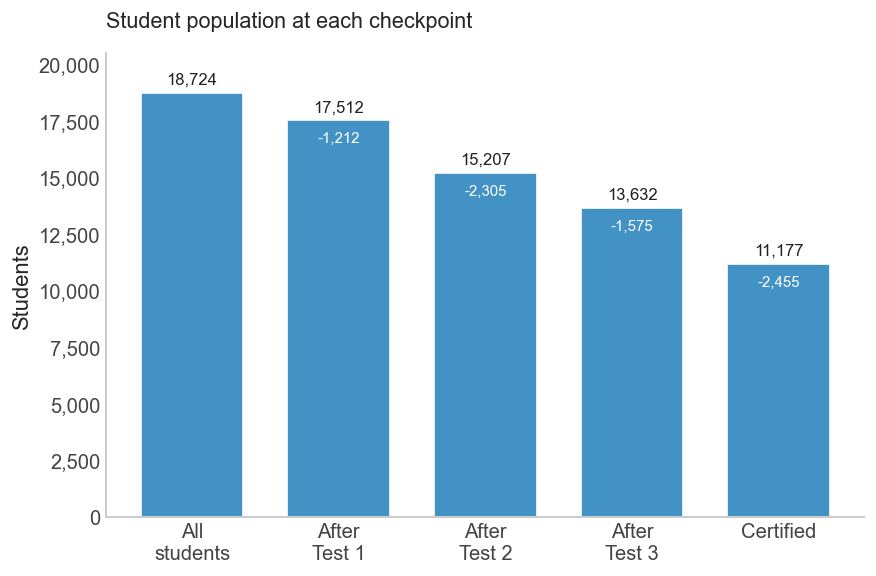

In [17]:
# Dropout cascade: population remaining at each checkpoint
BAR = '#4292c6'


def clean_axes(ax):
    """Removing gridlines, top and right spines, and tick marks."""
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#cccccc')
    ax.spines['bottom'].set_color('#cccccc')
    ax.tick_params(length=0, colors='#444444')


sizes = [len(cohorts[c]) for c in [1, 2, 3, 4]]
drops = [int((cohorts[c][TARGET_NAMES[c]] == 0).sum()) for c in [1, 2, 3, 4]]

labels = ['All\nstudents', 'After\nTest 1', 'After\nTest 2', 'After\nTest 3', 'Certified']
population = sizes + [sizes[-1] - drops[-1]]
lost = [0] + drops

fig, ax = plt.subplots(figsize=(7.5, 5))
bars = ax.bar(labels, population, color=BAR, width=0.7)

for bar, value, drop in zip(bars, population, lost):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 250,
            f'{value:,}', ha='center', va='bottom', fontsize=10, color='#222222')
    if drop:
        ax.text(bar.get_x() + bar.get_width() / 2, value - 500,
                f'-{drop:,}', ha='center', va='top', fontsize=9, color='white')

ax.set_title('Student population at each checkpoint', fontsize=13, pad=15, loc='left')
ax.set_ylabel('Students')
ax.set_ylim(0, 20500)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{int(x):,}'))
clean_axes(ax)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'population_cascade.png', dpi=200, bbox_inches='tight')
plt.show()

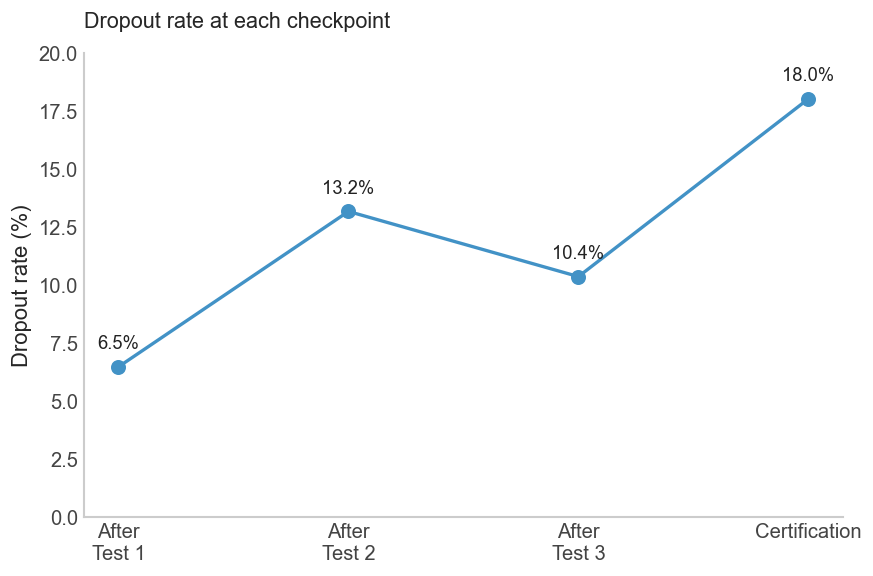

In [18]:
# Dropout rate within each cohort

checkpoints = ['After\nTest 1', 'After\nTest 2', 'After\nTest 3', 'Certification']
drop_rates  = [d / s * 100 for d, s in zip(drops, sizes)]

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(checkpoints, drop_rates, marker='o', markersize=8,
        linewidth=2, color=BAR, zorder=3)

for x, rate in zip(checkpoints, drop_rates):
    ax.text(x, rate + 0.6, f'{rate:.1f}%', ha='center', va='bottom',
            fontsize=11, color='#222222')

ax.set_title('Dropout rate at each checkpoint', fontsize=13, pad=15, loc='left')
ax.set_ylabel('Dropout rate (%)')
ax.set_ylim(0, 20)
clean_axes(ax)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'dropout_rate_by_cohort.png', dpi=200, bbox_inches='tight')
plt.show()

Two further exhibits follow. The first tracks mean session viewing across the course for each exit group, the only behavioural measure recorded against a point in the course. The second compares assessed performance within lifespan 4, where students have the same set of recorded assessments and are divided by the final dropout outcome.

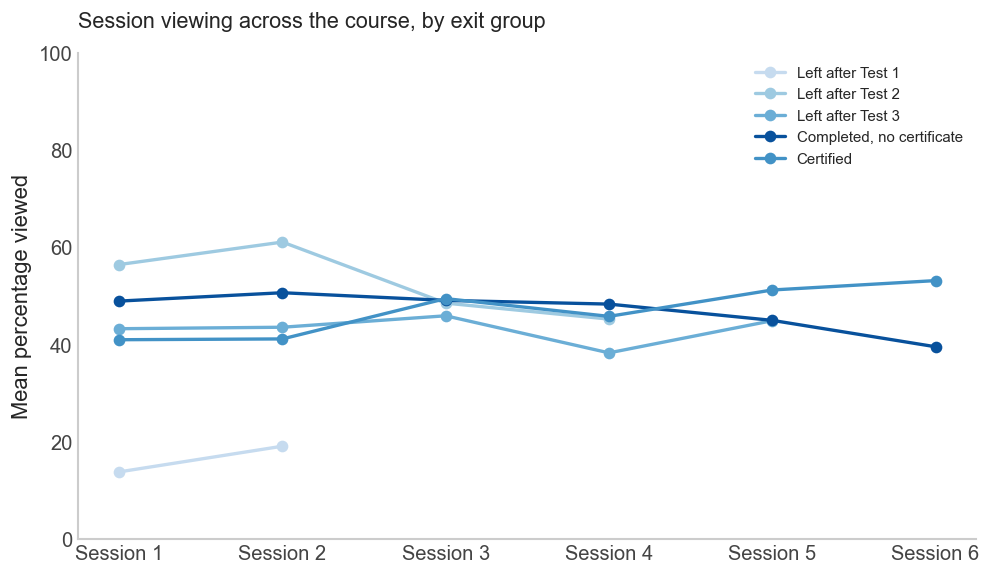


Mean percentage viewed:

                           session 1  session 2  session 3  session 4  session 5  session 6
Left after Test 1               13.8       19.1        NaN        NaN        NaN        NaN
Left after Test 2               56.4       61.1       48.5       45.2        NaN        NaN
Left after Test 3               43.3       43.6       45.9       38.3       44.9        NaN
Completed, no certificate       48.9       50.7       49.1       48.3       45.0       39.5
Certified                       41.0       41.2       49.4       45.8       51.2       53.1


In [19]:
# Mean percentage of each session viewed, by exit group.
# Held as a standalone Series so no column is added to df and nothing
# downstream can pick it up as a feature.
SESSION_COLS = ['session 1', 'session 2', 'session 3',
                'session 4', 'session 5', 'session 6']

def _exit_group(row):
    if row['lifespan'] < 4:
        return f"Left after Test {row['lifespan']}"
    return 'Completed, no certificate' if row['dropout'] == 'Y' else 'Certified'

EXIT_GROUP  = df.apply(_exit_group, axis=1)
GROUP_ORDER = ['Left after Test 1', 'Left after Test 2', 'Left after Test 3',
               'Completed, no certificate', 'Certified']

traj = df.groupby(EXIT_GROUP)[SESSION_COLS].mean().reindex(GROUP_ORDER)
traj.to_csv(TABLES_DIR / 'session_trajectory_by_group.csv')

COLOURS = {
    'Left after Test 1':         '#c6dbef',
    'Left after Test 2':         '#9ecae1',
    'Left after Test 3':         '#6baed6',
    'Completed, no certificate': '#08519c',
    'Certified':                 '#4292c6',
}

fig, ax = plt.subplots(figsize=(8.5, 5))
x = range(1, 7)

for group in GROUP_ORDER:
    ax.plot(x, traj.loc[group].values, marker='o', linewidth=2,
            color=COLOURS[group], label=group)

ax.set_xticks(list(x))
ax.set_xticklabels([f'Session {i}' for i in x])
ax.set_ylabel('Mean percentage viewed')
ax.set_ylim(0, 100)
ax.set_title('Session viewing across the course, by exit group',
             fontsize=13, pad=15, loc='left')
ax.legend(frameon=False, fontsize=9)
clean_axes(ax)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'session_trajectory_by_group.png',
            dpi=200, bbox_inches='tight')
plt.show()

print("\nMean percentage viewed:\n")
print(traj.round(1).to_string())

In [20]:
# Assessed performance of the two lifespan-4 outcomes.
# Grades were encoded to points in 1.4, so no mapping is applied here.
GRADED = ['test 1', 'test 2', 'test 3', 'ind cw', 'group cw', 'final grade']

ls4       = df[df['lifespan'] == 4]
no_cert   = ls4[ls4['dropout'] == 'Y']
certified = ls4[ls4['dropout'] == 'N']

ls4_grades = pd.DataFrame({
    f'No certificate (n={len(no_cert):,})': no_cert[GRADED].mean(),
    f'Certified (n={len(certified):,})':    certified[GRADED].mean(),
}).round(2)
ls4_grades['Difference'] = (ls4_grades.iloc[:, 1] - ls4_grades.iloc[:, 0]).round(2)

ls4_grades.to_csv(TABLES_DIR / 'lifespan4_grade_comparison.csv')

print("Table: Assessed performance within lifespan 4")
print("Mean grade points, A=4 to F=0.\n")
print(ls4_grades.to_string())

Table: Assessed performance within lifespan 4
Mean grade points, A=4 to F=0.

             No certificate (n=2,455)  Certified (n=11,177)  Difference
test 1                           2.36                  2.02       -0.34
test 2                           2.12                  2.13        0.01
test 3                           1.81                  2.14        0.33
ind cw                           2.02                  2.47        0.45
group cw                         1.94                  2.19        0.25
final grade                      1.62                  2.44        0.82


### Interpreting the exits and how the groups differ

The rate at the first checkpoint is the lowest of the four: 1,212 of 18,724 students leave after Test 1, a dropout rate of 6.5%. Cohort 1 is therefore the most imbalanced of the cohorts despite being the largest.

The rate at the final checkpoint is the highest, at 18.0%. Of the 13,632 students with recorded values for all six session fields and all assessments, 2,455 are labelled dropout = Y. Cohort 4 therefore asks a different question from the other three: it separates two groups with the same set of recorded assessment fields but different final outcome labels. The dataset contains no payment, certificate-claim, financial or administrative variable that directly explains this distinction. Whether their behaviour separates them is taken up below, and how far a model can exploit it is a question for Phase 2.

The rate does not rise steadily across the four checkpoints. It reaches 13.2% at Cohort 2, falls to 10.4% at Cohort 3, then rises to its maximum at Cohort 4.

The two groups that completed the course are not behaviourally identical while it runs. Students who did not certify view more of the first two sessions than those who did, 48.9% and 50.7% against 41.0% and 41.2%. At session 3 the groups are almost equal, at 49.1% and 49.4%. At session 4 the dropout = Y group is 2.5 percentage points higher, at 48.3% against 45.8%. A sustained reversal appears from session 5: 45.0% against 51.2%, followed by 39.5% against 53.1% at session 6. The group that ends without a certificate begins ahead by roughly nine points and ends behind by fourteen.

Assessed performance turns at the same points. The non-certifying group scores 2.36 grade points at Test 1 against 2.02, is level at Test 2 at 2.12 against 2.13, falls behind at Test 3 at 1.81 against 2.14, and ends 0.82 points behind at final grade. Two measures recorded independently of one another, attendance and assessment, change direction at the same three stages. This is not a group that fails from the outset; it enters ahead of the students who certify and declines from the middle of the course onwards. What the data cannot establish is the order of events. A student who decides part-way through not to continue paying might disengage as a consequence, or disengagement might come first. No payment, financial or administrative variable is recorded, so neither reading can be tested here.

The students who leave before completing differ among themselves as much as they differ from those who stay. Those who leave after Test 1 view 13.8% and 19.1% of the first two sessions, barely attending before they go. Those who leave after Test 2 view 56.4% and 61.1%, the highest of any group in the dataset including the students who go on to certify. Leaving early is not one behaviour, and a model built on attendance alone would have to separate the least engaged students in the course from the most engaged.

## 1.9 Saving the cohort datasets

Each cohort has two feature variants, initially written as Parquet:

- `cohort_N.parquet`, with retrospective amortised engagement columns
- `cohort_N_noeng.parquet`, without the engagement columns

Parquet is the primary machine-readable format because it preserves column
dtypes. The following section also writes CSV copies for direct inspection and
submission.

The eight Parquet files are intended as the processed inputs for Phase 2.
Later notebooks should read these processed files rather than rebuilding
cohorts from the raw CSV.

In [21]:
# Saving all cohort datasets to Parquet
for c_num in [1, 2, 3, 4]:
    # With engagement
    path_eng = PROCESSED_DIR / f'cohort_{c_num}.parquet'
    cohorts[c_num].to_parquet(path_eng, index=False)
    
    # Without engagement
    path_noeng = PROCESSED_DIR / f'cohort_{c_num}_noeng.parquet'
    cohorts_noeng[c_num].to_parquet(path_noeng, index=False)

print("Saved cohort datasets to data/processed/:")
for c_num in [1, 2, 3, 4]:
    c_eng = cohorts[c_num]
    c_noeng = cohorts_noeng[c_num]
    print(f"  cohort_{c_num}.parquet        {len(c_eng):>6,} rows, {len(c_eng.columns):>2} cols")
    print(f"  cohort_{c_num}_noeng.parquet  {len(c_noeng):>6,} rows, {len(c_noeng.columns):>2} cols")

Saved cohort datasets to data/processed/:
  cohort_1.parquet        18,724 rows,  9 cols
  cohort_1_noeng.parquet  18,724 rows,  6 cols
  cohort_2.parquet        17,512 rows, 12 cols
  cohort_2_noeng.parquet  17,512 rows,  9 cols
  cohort_3.parquet        15,207 rows, 14 cols
  cohort_3_noeng.parquet  15,207 rows, 11 cols
  cohort_4.parquet        13,632 rows, 18 cols
  cohort_4_noeng.parquet  13,632 rows, 15 cols


CSV copies of all eight files are written to `data/processed/csv/`. Parquet cannot be opened without Python, and the supporting data submitted with the report needs to be readable directly.

In [22]:
# Saving CSV copies of all cohort datasets
CSV_DIR = PROCESSED_DIR / 'csv'
CSV_DIR.mkdir(parents=True, exist_ok=True)

for c_num in [1, 2, 3, 4]:
    # With engagement
    cohorts[c_num].to_csv(CSV_DIR / f'cohort_{c_num}.csv', index=False)
    # Without engagement
    cohorts_noeng[c_num].to_csv(CSV_DIR / f'cohort_{c_num}_noeng.csv', index=False)

print(f'CSV copies saved to {CSV_DIR}/:')
for f in sorted(CSV_DIR.iterdir()):
    print(f'  {f.name:<30} ({f.stat().st_size:>8,} bytes)')

CSV copies saved to data/processed/csv/:
  cohort_1.csv                   ( 541,740 bytes)
  cohort_1_noeng.csv             ( 255,848 bytes)
  cohort_2.csv                   ( 734,136 bytes)
  cohort_2_noeng.csv             ( 481,803 bytes)
  cohort_3.csv                   ( 764,136 bytes)
  cohort_3_noeng.csv             ( 553,555 bytes)
  cohort_4.csv                   ( 902,213 bytes)
  cohort_4_noeng.csv             ( 727,174 bytes)


## 1.10 Final summary table

One row per cohort: checkpoint, size, feature counts for both variants, target split, and a missing-value count that should read zero throughout. Saved to `outputs/tables/cohort_summary.csv`.

In [23]:
# Final summary table
summary_rows = []

for c_num in [1, 2, 3, 4]:
    c_df = cohorts[c_num]
    target = TARGET_NAMES[c_num]
    n_features_eng = len(c_df.columns) - 1
    n_features_noeng = len(cohorts_noeng[c_num].columns) - 1
    n_survive = (c_df[target] == 1).sum()
    n_drop = (c_df[target] == 0).sum()
    drop_rate = n_drop / len(c_df) * 100
    
    summary_rows.append({
        'Cohort': c_num,
        'Checkpoint': ['After Test 1', 'After Test 2', 'After Test 3', 'Certificate'][c_num - 1],
        'Students': len(c_df),
        'Features (with eng.)': n_features_eng,
        'Features (no eng.)': n_features_noeng,
        'Survive': n_survive,
        'Drop': n_drop,
        'Drop Rate (%)': round(drop_rate, 1),
        'Missing Values': c_df.isnull().sum().sum(),
        'Target Column': target
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(TABLES_DIR / 'cohort_summary.csv', index=False)

print("Data Preparation Summary")
print("=" * 100)
print(summary_df.to_string(index=False))
print("\nSummary saved to outputs/tables/cohort_summary.csv")

Data Preparation Summary
 Cohort   Checkpoint  Students  Features (with eng.)  Features (no eng.)  Survive  Drop  Drop Rate (%)  Missing Values           Target Column
      1 After Test 1     18724                     8                   5    17512  1212            6.5               0        survives_phase_1
      2 After Test 2     17512                    11                   8    15207  2305           13.2               0        survives_phase_2
      3 After Test 3     15207                    13                  10    13632  1575           10.4               0        survives_phase_3
      4  Certificate     13632                    17                  14    11177  2455           18.0               0 survives_to_certificate

Summary saved to outputs/tables/cohort_summary.csv


## Summary

What this notebook produced:

1. Loaded the raw dataset of 18,724 students across 18 columns.
2. Confirmed the missingness is monotone and coextensive with the dropout label.
3. Encoded the categorical columns ordinally: grades A=4 to F=0, year first=1 to third=3, external Y=1 and N=0.
4. Derived each student's lifespan, 1 to 4, from where their record ends.
5. Built four cohort datasets, each containing only the students present at that checkpoint, only the features available by then, an engineered binary survival target, and no missing values.
6. Amortised `forum Q`, `forum A` and `office hour visits` across the phases each student was present for.
7. Saved a second variant of each cohort with the three engagement columns removed, giving eight files in total, so Phase 2 can measure how much performance depends on them.
8. Checked every count with assertions that halt on failure.
9. Compared session viewing and assessed performance across the exit groups, establishing that the two lifespan-4 outcomes diverge from the middle of the course rather than only at the certificate stage.

No imputation was performed at any point. Missing values were handled by the cohort design: students who left are excluded from later cohorts rather than having invented values inserted.

### Handover to Phase 2

Phase 2 loads the eight cohort files and fits five classifiers to each cohort, twenty in total, selecting per cohort rather than assuming one model suits all four. Cohort sizes fall and feature counts rise across the sequence, so the best model may differ by cohort.